🛰️ Iniciando conexão com o Google Earth Engine...
✅ Conectado com sucesso!
☁️ Filtrando imagens do Sentinel-2 e calculando NDVI...
📊 Extraindo a série temporal (Isso pode demorar um minutinho)...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Análise concluída! Gráfico e dados exportados com sucesso.


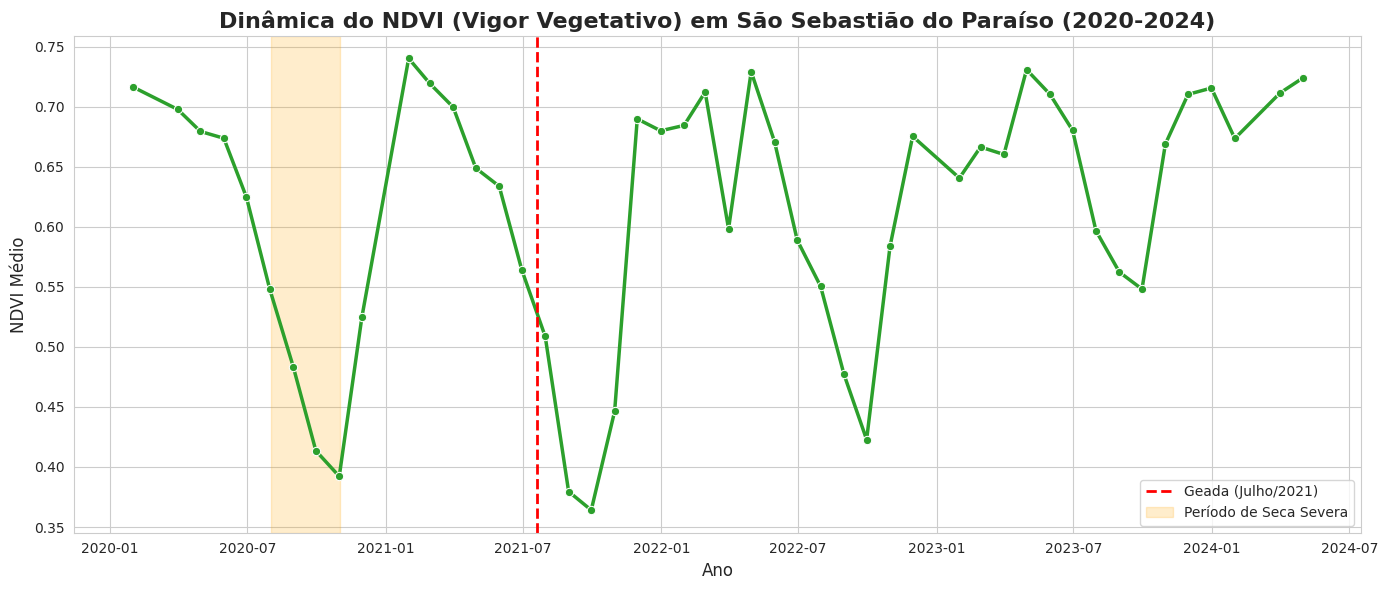

In [ ]:
# Instalar a biblioteca do Earth Engine (se necessário)
!pip install earthengine-api pandas matplotlib seaborn --quiet

import ee
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

print("🛰️ Iniciando conexão com o Google Earth Engine...")

# 1. Autenticação (Vai abrir um link para você logar com sua conta Google)
# ATENÇÃO: O GEE agora exige um 'Projeto Cloud'. Crie um gratuitamente no site do GEE se ainda não tiver.
try:
    ee.Initialize(project='spatial-garage-267618') # Substitua pelo ID do seu projeto GEE
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='spatial-garage-267618')

print("✅ Conectado com sucesso!")

# 2. Definir a Área de Interesse (São Sebastião do Paraíso)
# Usando um ponto central e um buffer (raio) de 15km para pegar a região agrícola.
# No TCC final, você pode trocar isso pelo shapefile exato dos talhões de café!
ponto_ssp = ee.Geometry.Point([-46.991, -20.917])
roi = ponto_ssp.buffer(15000)

# 3. Definir o período do estudo (Pré-seca/geada até a Safra de 2024)
data_inicio = '2020-01-01'
data_fim = '2024-05-01'

# 4. Função para limpar nuvens e calcular o NDVI
def processar_imagem(image):
    # Máscara de nuvens do Sentinel-2 (Banda QA60)
    qa = image.select('QA60')
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11
    mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(qa.bitwiseAnd(cirrusBitMask).eq(0))

    # Calcular NDVI: (Infravermelho Próximo - Vermelho) / (Infravermelho Próximo + Vermelho)
    # No Sentinel-2: (B8 - B4) / (B8 + B4)
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

    return image.updateMask(mask).addBands(ndvi).copyProperties(image, ["system:time_start"])

# 5. Baixar e processar a Coleção de Imagens
print("☁️ Filtrando imagens do Sentinel-2 e calculando NDVI...")
colecao = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(roi)
           .filterDate(data_inicio, data_fim)
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 15)) # Apenas imagens com menos de 15% de nuvens
           .map(processar_imagem))

# 6. Extrair a média de NDVI da região para cada imagem
def extrair_dados(image):
    media = image.select('NDVI').reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=roi,
        scale=10, # 10 metros de resolução
        maxPixels=1e9
    )
    return ee.Feature(None, {
        'Data': image.date().format('YYYY-MM-dd'),
        'NDVI': media.get('NDVI')
    })

print("📊 Extraindo a série temporal (Isso pode demorar um minutinho)...")
serie_temporal = colecao.map(extrair_dados).getInfo()

# 7. Transformar em Tabela (Pandas DataFrame)
dados = [feat['properties'] for feat in serie_temporal['features']]
df = pd.DataFrame(dados)
df['Data'] = pd.to_datetime(df['Data'])
df = df.dropna().sort_values('Data')

# Agrupar por mês para suavizar o gráfico (Média Mensal)
df_mensal = df.resample('M', on='Data').mean().reset_index()

# 8. Visualização Estilo Artigo Científico
plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")
sns.lineplot(data=df_mensal, x='Data', y='NDVI', color='#2ca02c', linewidth=2.5, marker='o')

# Destacar os eventos climáticos
plt.axvline(pd.to_datetime('2021-07-20'), color='red', linestyle='--', linewidth=2, label='Geada (Julho/2021)')
plt.axvspan(pd.to_datetime('2020-08-01'), pd.to_datetime('2020-11-01'), color='orange', alpha=0.2, label='Período de Seca Severa')

plt.title('Dinâmica do NDVI (Vigor Vegetativo) em São Sebastião do Paraíso (2020-2024)', fontsize=16, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('NDVI Médio', fontsize=12)
plt.legend()
plt.tight_layout()

# Exportar Gráfico e Tabela
nome_grafico = 'Serie_Temporal_NDVI_SSP.png'
nome_tabela = 'Dados_NDVI_SSP_Mensal.csv'

plt.savefig(nome_grafico, dpi=300)
df_mensal.to_csv(nome_tabela, index=False, sep=';', decimal=',')

files.download(nome_grafico)
files.download(nome_tabela)

print(f"✅ Análise concluída! Gráfico e dados exportados com sucesso.")

🔐 Autenticando...
🌍 Conectando ao Earth Engine...
🛰️ Iniciando varredura do Landsat 8. Aguarde...

📡 Seca (2014-2016): 141 imagens orbitais encontradas e processadas.
📡 Geada (2021-2023): 148 imagens orbitais encontradas e processadas.

📊 Desenhando os gráficos de resiliência fisiológica...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Sucesso absoluto! O gráfico final e a tabela estão sendo baixados para o seu computador.


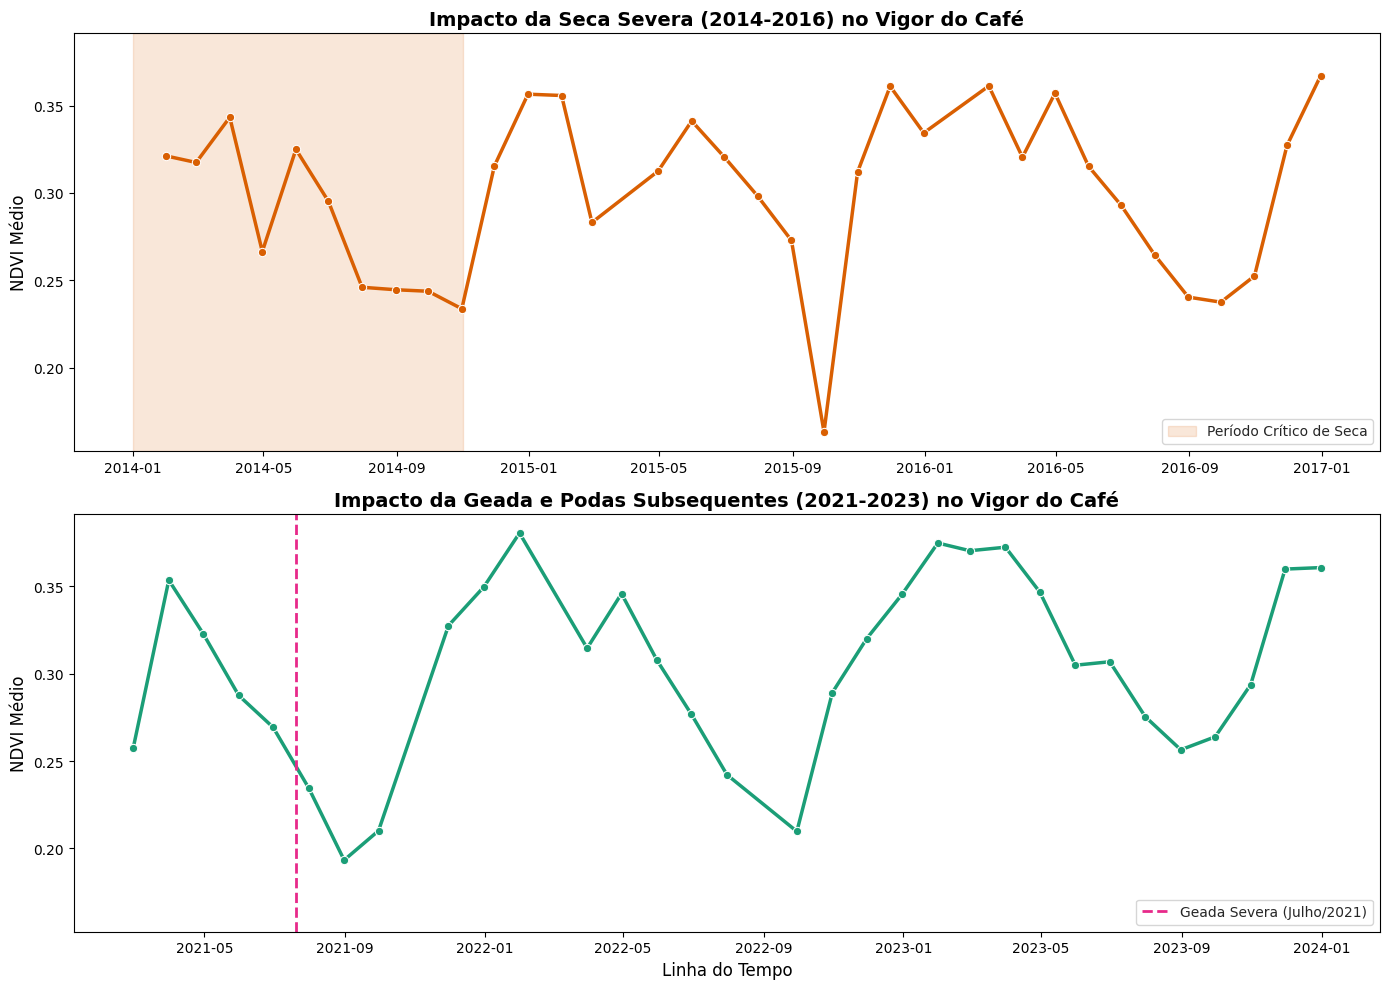

In [ ]:
!pip install earthengine-api pandas matplotlib seaborn --quiet

from google.colab import auth
import ee
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

print("🔐 Autenticando...")
auth.authenticate_user()

print("🌍 Conectando ao Earth Engine...")
# ATENÇÃO: Coloque o ID do seu projeto do GEE aqui dentro das aspas!
ee.Initialize(project='spatial-garage-267618')

# 1. Definir a Área de Estudo (A SOLUÇÃO INFALÍVEL)
# Usamos um ponto central e filtramos o polígono oficial que "encosta" nesse ponto.
ponto_ssp = ee.Geometry.Point([-46.991, -20.917])
municipio = ee.FeatureCollection("FAO/GAUL/2015/level2").filterBounds(ponto_ssp)
roi = municipio.geometry()

# 2. Carregar o MapBiomas (Coleção 9.0 Atualizada)
mapbiomas = ee.Image('projects/mapbiomas-public/assets/brazil/lulc/collection9/mapbiomas_collection90_integration_v1')

# Criar máscaras dinâmicas de Café (Classe 46) para os anos exatos
mascara_cafe_2014 = mapbiomas.select('classification_2014').eq(46)
mascara_cafe_2021 = mapbiomas.select('classification_2021').eq(46)

# 3. Função para processar o Landsat 8 (Nuvem + NDVI + Máscara)
def processar_landsat(image, mascara):
    qa = image.select('QA_PIXEL')
    cloud_shadow_bit_mask = (1 << 3)
    clouds_bit_mask = (1 << 4)
    mask_nuvem = qa.bitwiseAnd(cloud_shadow_bit_mask).eq(0) \
                 .And(qa.bitwiseAnd(clouds_bit_mask).eq(0))

    ndvi = image.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
    mask_final = mask_nuvem.And(mascara)

    return image.updateMask(mask_final).addBands(ndvi).copyProperties(image, ["system:time_start"])

# 4. Configurar as duas janelas de extração
janelas = {
    'Seca (2014-2016)': {'inicio': '2014-01-01', 'fim': '2016-12-31', 'mascara': mascara_cafe_2014},
    'Geada (2021-2023)': {'inicio': '2021-01-01', 'fim': '2023-12-31', 'mascara': mascara_cafe_2021}
}

resultados_finais = []

print("🛰️ Iniciando varredura do Landsat 8. Aguarde...\n")

for nome_evento, params in janelas.items():
    colecao = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
               .filterBounds(roi)
               .filterDate(params['inicio'], params['fim'])
               .filter(ee.Filter.lt('CLOUD_COVER', 30))
               .map(lambda img: processar_landsat(img, params['mascara'])))

    # Aviso no console para monitorar o andamento
    tamanho = colecao.size().getInfo()
    print(f"📡 {nome_evento}: {tamanho} imagens orbitais encontradas e processadas.")

    if tamanho == 0:
        continue

    def extrair_media(image):
        media = image.select('NDVI').reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi,
            scale=30, # Resolução nativa do Landsat e do MapBiomas
            maxPixels=1e9
        )
        return ee.Feature(None, {
            'Data': image.date().format('YYYY-MM-dd'),
            'NDVI': media.get('NDVI'),
            'Evento': nome_evento
        })

    serie = colecao.map(extrair_media).getInfo()
    dados = [feat['properties'] for feat in serie['features'] if feat['properties']['NDVI'] is not None]
    resultados_finais.extend(dados)

# 5. Organizar os dados e gerar gráficos
if not resultados_finais:
    print("\n❌ ERRO: Nenhum dado de café foi encontrado. O limite da cidade pode não ter cruzado com os dados do MapBiomas.")
else:
    print("\n📊 Desenhando os gráficos de resiliência fisiológica...")
    df = pd.DataFrame(resultados_finais)
    df['Data'] = pd.to_datetime(df['Data'])
    df = df.sort_values('Data')

    df_mensal = df.groupby(['Evento', pd.Grouper(key='Data', freq='ME')])['NDVI'].mean().reset_index()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharey=True)
    sns.set_style("whitegrid")

    df_seca = df_mensal[df_mensal['Evento'] == 'Seca (2014-2016)']
    sns.lineplot(data=df_seca, x='Data', y='NDVI', ax=ax1, color='#d95f02', linewidth=2.5, marker='o')
    ax1.axvspan(pd.to_datetime('2014-01-01'), pd.to_datetime('2014-11-01'), color='#d95f02', alpha=0.15, label='Período Crítico de Seca')
    ax1.set_title('Impacto da Seca Severa (2014-2016) no Vigor do Café', fontsize=14, fontweight='bold')
    ax1.set_ylabel('NDVI Médio', fontsize=12)
    ax1.set_xlabel('')
    ax1.legend(loc='lower right')

    df_geada = df_mensal[df_mensal['Evento'] == 'Geada (2021-2023)']
    sns.lineplot(data=df_geada, x='Data', y='NDVI', ax=ax2, color='#1b9e77', linewidth=2.5, marker='o')
    ax2.axvline(pd.to_datetime('2021-07-20'), color='#e7298a', linestyle='--', linewidth=2, label='Geada Severa (Julho/2021)')
    ax2.set_title('Impacto da Geada e Podas Subsequentes (2021-2023) no Vigor do Café', fontsize=14, fontweight='bold')
    ax2.set_ylabel('NDVI Médio', fontsize=12)
    ax2.set_xlabel('Linha do Tempo', fontsize=12)
    ax2.legend(loc='lower right')

    plt.tight_layout()

    nome_grafico = 'Comparativo_NDVI_MapBiomas_Corrigido.png'
    nome_tabela = 'Dados_NDVI_MapBiomas_Landsat.csv'
    plt.savefig(nome_grafico, dpi=300)
    df_mensal.to_csv(nome_tabela, index=False, sep=';', decimal=',')

    files.download(nome_grafico)
    files.download(nome_tabela)

    print("✅ Sucesso absoluto! O gráfico final e a tabela estão sendo baixados para o seu computador.")

In [ ]:
"""
=====================================================================
TCC - Extração Fenológica de Clima (Tmin/Precipitação) e NDVI Histórico
via Google Earth Engine - Sul de Minas Gerais

Corrige o script original em três pontos:
  1. Extração POR MUNICÍPIO (não um único ponto para toda a microrregião)
  2. Adiciona PRECIPITAÇÃO, não só temperatura
  3. Agrega em JANELAS FENOLÓGICAS (florada, enchimento de grãos, inverno)
     em vez de série diária bruta

Além disso, adiciona a extração de NDVI histórico via Landsat 5/7/8
(1988-2014, antes do Sentinel-2) COM calibração cruzada no período de
sobreposição (2015-2020), para evitar viés de sensor ao unir com a
série moderna de Sentinel-2.

Rode este script no Google Colab (precisa de conta Earth Engine ativa).
=====================================================================
"""

import ee
import pandas as pd
import numpy as np

MEU_PROJETO = 'spatial-garage-267618'  # ajuste para o seu Project ID

try:
    ee.Initialize(project=MEU_PROJETO)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=MEU_PROJETO)

# =====================================================================
# 1. GEOMETRIAS DOS 10 MUNICÍPIOS
# =====================================================================
# Tenta resolver via FAO GAUL (limites administrativos nível 2). Se o
# nome não bater exatamente (acentuação, grafia), cai no fallback de
# centróide fixo (coordenadas aproximadas da sede municipal).
MUNICIPIOS = [
    "Arceburgo", "Cabo Verde", "Guaranesia", "Guaxupe", "Itamogi",
    "Jacui", "Juruaia", "Monte Belo", "Muzambinho", "Nova Resende"
]

# Fallback: coordenadas aproximadas da sede de cada município (lon, lat).
# Usadas apenas se o município não for encontrado no GAUL.
CENTROIDES_FALLBACK = {
    "Arceburgo":    (-46.9611, -21.3781),
    "Cabo Verde":   (-46.3961, -21.4586),
    "Guaranesia":   (-46.9922, -21.3892),
    "Guaxupe":      (-46.7136, -21.3053),
    "Itamogi":      (-46.7758, -21.2914),
    "Jacui":        (-46.6353, -21.0175),
    "Juruaia":      (-46.8983, -21.3494),
    "Monte Belo":   (-46.3689, -21.2861),
    "Muzambinho":   (-46.5236, -21.3739),
    "Nova Resende": (-46.4319, -21.1808),
}

gaul = ee.FeatureCollection("FAO/GAUL/2015/level2") \
    .filter(ee.Filter.eq('ADM1_NAME', 'Minas Gerais'))


def obter_geometria_municipio(nome):
    """Tenta casar pelo GAUL; se falhar, usa buffer de 5km no centróide fallback."""
    try:
        feat = gaul.filter(ee.Filter.eq('ADM2_NAME', nome)).first()
        geom_info = ee.Feature(feat).geometry().getInfo()
        if geom_info is not None:
            return ee.Feature(feat).geometry(), 'GAUL'
    except Exception:
        pass

    lon, lat = CENTROIDES_FALLBACK[nome]
    return ee.Geometry.Point([lon, lat]).buffer(5000), 'FALLBACK_BUFFER_5KM'


geometrias = {}
for nome in MUNICIPIOS:
    geom, fonte = obter_geometria_municipio(nome)
    geometrias[nome] = geom
    print(f"[INFO] {nome}: geometria resolvida via {fonte}")


# =====================================================================
# 2. JANELAS FENOLÓGICAS (ajuste os meses conforme sua revisão bibliográfica)
# =====================================================================
JANELAS_FENOLOGICAS = {
    'Florada': [9, 10, 11],                 # set-out-nov
    'Enchimento_Graos': [12, 1, 2, 3, 4],    # dez-abr (expansão/enchimento)
    'Inverno_Risco_Geada': [6, 7, 8],        # jun-jul-ago
}


def construir_pegada_cafe_municipio(nome, geom_municipio, anos_ancora=(2000, 2010, 2015, 2020, 2023)):
    """Constrói a 'pegada estável de café' do município: a união dos pixels
    classificados como café em qualquer um dos anos-âncora informados,
    vetorizada e recortada ao limite municipal.

    Usada como geometria de extração tanto para clima (ERA5-Land) quanto
    para NDVI, em vez do polígono administrativo inteiro - importante
    especialmente em municípios que se estendem por mais de um pixel de
    clima (~11km), onde a área de café tende a se concentrar em encostas,
    não em fundos de vale (Assad et al., 2004).

    SIMPLIFICAÇÃO DECLARADA: usa uma pegada estática (união multi-anos) em
    vez de recalcular a máscara ano a ano para o clima, por custo
    computacional. Isso deve ser mencionado como limitação na Metodologia:
    a extensão exata da lavoura pode ter mudado dentro do período 1988-2023,
    e a pegada estável é uma aproximação da área historicamente cafeeira.
    """
    mascara_uniao = None
    for ano in anos_ancora:
        m = obter_mascara_cafe(ano)
        mascara_uniao = m if mascara_uniao is None else mascara_uniao.unmask(0).Or(m.unmask(0))

    mascara_uniao = mascara_uniao.selfMask().clip(geom_municipio)

    vetores = mascara_uniao.reduceToVectors(
        geometry=geom_municipio, scale=30, geometryType='polygon',
        eightConnected=True, maxPixels=1e9, bestEffort=True
    )
    geometria_cafe = vetores.geometry()

    # Fallback: se a pegada de café ficar vazia (ex.: erro de classificação
    # ou município sem café detectado nos anos-âncora), usa o polígono
    # municipal inteiro para não perder o município da análise.
    area_cafe = geometria_cafe.area(1).getInfo()
    if area_cafe is None or area_cafe < 1000:  # menos de 0.1 ha é ruído
        print(f"[AVISO] Pegada de café vazia/insignificante em {nome} - "
              f"usando o polígono municipal inteiro como fallback.")
        return geom_municipio, False

    return geometria_cafe, True


# =====================================================================
# 3. EXTRAÇÃO DE CLIMA (ERA5-Land) POR MUNICÍPIO E ANO
# =====================================================================
def extrair_clima_municipio(nome, geom, ano_inicio=1988, ano_fim=2024):
    print(f"\n[INFO] Extraindo clima de {nome} ({ano_inicio}-{ano_fim})...")

    colecao = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR") \
        .select(['temperature_2m_min', 'total_precipitation_sum']) \
        .filterBounds(geom) \
        .filterDate(f'{ano_inicio}-01-01', f'{ano_fim}-01-01')

    def extrair_dia(img):
        data = img.date()
        valores = img.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geom,
            scale=11132,
            bestEffort=True
        )
        tmin_c = ee.Number(valores.get('temperature_2m_min')).subtract(273.15)
        precip_mm = ee.Number(valores.get('total_precipitation_sum')).multiply(1000)  # m -> mm
        return ee.Feature(None, {
            'Ano': data.get('year'),
            'Mes': data.get('month'),
            'Dia': data.get('day'),
            'Tmin_C': tmin_c,
            'Precip_mm': precip_mm,
        })

    # Processa ano a ano para não estourar o limite de elementos do getInfo()
    registros = []
    for ano in range(ano_inicio, ano_fim):
        colecao_ano = colecao.filterDate(f'{ano}-01-01', f'{ano+1}-01-01')
        feats = colecao_ano.map(extrair_dia).getInfo()['features']
        for f in feats:
            p = f['properties']
            if p.get('Tmin_C') is not None:
                registros.append(p)

    df = pd.DataFrame(registros)
    df['Municipio'] = nome
    return df


def agregar_indicadores_anuais(df_diario):
    """Converte a série diária em indicadores anuais e fenológicos."""
    linhas = []
    for (mun, ano), grupo in df_diario.groupby(['Municipio', 'Ano']):
        registro = {
            'Municipio': mun,
            'Ano': ano,
            'Tmin_Abs': grupo['Tmin_C'].min(),
            'Precip_Anual': grupo['Precip_mm'].sum(),
            'Dias_Abaixo_3C': (grupo[grupo['Mes'].isin(JANELAS_FENOLOGICAS['Inverno_Risco_Geada'])]['Tmin_C'] < 3).sum(),
        }
        for janela, meses in JANELAS_FENOLOGICAS.items():
            sub = grupo[grupo['Mes'].isin(meses)]
            registro[f'Precip_{janela}'] = sub['Precip_mm'].sum()
            registro[f'Tmin_Abs_{janela}'] = sub['Tmin_C'].min() if not sub.empty else np.nan
        linhas.append(registro)
    return pd.DataFrame(linhas)


# =====================================================================
# 4. MÁSCARA DE CAFÉ (MapBiomas) - restringe a extração de NDVI aos
#    pixels efetivamente classificados como lavoura cafeeira, eliminando
#    ruído espectral de pastagem, mata ciliar e vegetação nativa
#    adjacente às lavouras (o mesmo princípio da máscara EPAMIG proposta
#    originalmente na Metodologia, mas usando uma fonte nativa do GEE,
#    disponível também para os anos históricos de 1985 em diante).
# =====================================================================
MAPBIOMAS_ASSET = 'projects/mapbiomas-public/assets/brazil/lulc/v1'
CODIGO_CLASSE_CAFE = 46  # "Café" na legenda MapBiomas (Coleções 7-10)


def obter_mascara_cafe(ano):
    """Retorna uma ee.Image binária (1 = café, mascarado nos demais pixels)
    para o ano especificado, a partir da classificação MapBiomas daquele
    ano. Anos fora do intervalo 1985-2023 usam o ano válido mais próximo."""
    ano_valido = min(max(ano, 1985), 2023)
    colecao = ee.ImageCollection(MAPBIOMAS_ASSET)
    imagem_ano = colecao.filter(ee.Filter.calendarRange(ano_valido, ano_valido, 'year')).first()
    classificacao = ee.Image(imagem_ano).select('classification')
    mascara_cafe = classificacao.eq(CODIGO_CLASSE_CAFE).selfMask()
    return mascara_cafe


def calcular_area_cafe_municipio(nome, geom, ano):
    """Calcula a área (ha) classificada como café dentro do município,
    no ano especificado - útil como métrica complementar/validação
    cruzada contra a área colhida oficial do SIDRA."""
    mascara = obter_mascara_cafe(ano)
    area_img = mascara.multiply(ee.Image.pixelArea()).divide(10000)  # m² -> ha
    area_ha = area_img.reduceRegion(
        reducer=ee.Reducer.sum(), geometry=geom, scale=30, bestEffort=True, maxPixels=1e9
    ).get('classification')
    valor = area_ha.getInfo() if area_ha is not None else 0
    return valor if valor is not None else 0


def exportar_mascara_cafe_microrregiao(geometrias_dict, ano_referencia=2023,
                                        nome_arquivo='TCC_Mascara_Cafe_MapBiomas_SSP'):
    """Exporta a máscara de café (vetorizada) da microrregião inteira para
    o Google Drive, em formato SHP, para inspeção visual em QGIS/ArcGIS.
    Roda de forma assíncrona - acompanhe o progresso na aba 'Tasks' do
    editor de código do Earth Engine (code.earthengine.google.com/tasks)."""
    microrregiao = ee.FeatureCollection(list(geometrias_dict.values())).geometry().dissolve()
    mascara = obter_mascara_cafe(ano_referencia).clip(microrregiao)

    vetores = mascara.reduceToVectors(
        geometry=microrregiao,
        scale=30,
        geometryType='polygon',
        eightConnected=True,
        maxPixels=1e10,
        bestEffort=True
    )

    tarefa = ee.batch.Export.table.toDrive(
        collection=vetores,
        description=nome_arquivo,
        fileFormat='SHP'
    )
    tarefa.start()
    print(f"[INFO] Exportação da máscara de café ({ano_referencia}) iniciada.")
    print("       Acompanhe em: https://code.earthengine.google.com/tasks")
    print(f"       Arquivo aparecerá no seu Google Drive como '{nome_arquivo}.shp' (+ auxiliares).")
    return tarefa


# =====================================================================
# 5. NDVI HISTÓRICO VIA LANDSAT (1988-2014) COM CALIBRAÇÃO CRUZADA
#    (Agora restrito à máscara de café MapBiomas do respectivo ano)
# =====================================================================
def mascara_nuvem_landsat_c2(img):
    qa = img.select('QA_PIXEL')
    mascara_nuvem = qa.bitwiseAnd(1 << 3).eq(0)  # bit 3 = nuvem
    mascara_sombra = qa.bitwiseAnd(1 << 4).eq(0)  # bit 4 = sombra de nuvem
    return img.updateMask(mascara_nuvem).updateMask(mascara_sombra)


def calcular_ndvi_landsat(img, banda_nir, banda_red):
    # Fator de escala do Collection 2, Level 2 (reflectância de superfície)
    nir = img.select(banda_nir).multiply(0.0000275).add(-0.2)
    red = img.select(banda_red).multiply(0.0000275).add(-0.2)
    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    return img.addBands(ndvi)


def obter_colecao_landsat_ndvi(ano_inicio, ano_fim):
    """Combina Landsat 5, 7 e 8 em uma única coleção de NDVI, incluindo
    apenas os sensores cuja janela de cobertura realmente se sobrepõe ao
    intervalo [ano_inicio, ano_fim] solicitado - evita intervalos de data
    invertidos (ex.: pedir 2015-2021 e tentar filtrar o Landsat 5, que só
    cobre até 2012, gerando um range com fim antes do início)."""

    colecoes = []

    # Landsat 5: cobertura útil até ~2012
    if ano_inicio <= 2012 and ano_fim >= 1988:
        ini, fim = max(ano_inicio, 1988), min(ano_fim, 2012)
        if ini <= fim:
            l5 = ee.ImageCollection("LANDSAT/LT05/C02/T1_L2") \
                .filterDate(f'{ini}-01-01', f'{fim + 1}-01-01') \
                .map(mascara_nuvem_landsat_c2) \
                .map(lambda img: calcular_ndvi_landsat(img, 'SR_B4', 'SR_B3'))
            colecoes.append(l5)

    # Landsat 7: cobertura a partir de 1999 (SLC-off após 2003, mas ainda utilizável)
    if ano_fim >= 1999:
        ini, fim = max(ano_inicio, 1999), ano_fim
        if ini <= fim:
            l7 = ee.ImageCollection("LANDSAT/LE07/C02/T1_L2") \
                .filterDate(f'{ini}-01-01', f'{fim + 1}-01-01') \
                .map(mascara_nuvem_landsat_c2) \
                .map(lambda img: calcular_ndvi_landsat(img, 'SR_B4', 'SR_B3'))
            colecoes.append(l7)

    # Landsat 8: cobertura a partir de 2013
    if ano_fim >= 2013:
        ini, fim = max(ano_inicio, 2013), ano_fim
        if ini <= fim:
            l8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2") \
                .filterDate(f'{ini}-01-01', f'{fim + 1}-01-01') \
                .map(mascara_nuvem_landsat_c2) \
                .map(lambda img: calcular_ndvi_landsat(img, 'SR_B5', 'SR_B4'))
            colecoes.append(l8)

    if not colecoes:
        raise ValueError(f"Nenhum sensor Landsat cobre o intervalo {ano_inicio}-{ano_fim}.")

    colecao_final = colecoes[0]
    for c in colecoes[1:]:
        colecao_final = colecao_final.merge(c)
    return colecao_final


def extrair_ndvi_landsat_municipio(nome, geom, ano_inicio=1988, ano_fim=2015, usar_mascara_cafe=True):
    """Extrai o NDVI médio do Landsat em CADA janela fenológica (Florada,
    Enchimento_Graos, Inverno_Risco_Geada), não apenas no inverno - espelha
    a mesma lógica de JANELAS_FENOLOGICAS usada na extração de clima."""
    print(f"[INFO] Extraindo NDVI histórico (Landsat) de {nome}, todas as fases fenológicas...")
    colecao = obter_colecao_landsat_ndvi(ano_inicio, ano_fim).select('NDVI').filterBounds(geom)

    registros = []
    for ano in range(ano_inicio, ano_fim):
        registro = {'Municipio': nome, 'Ano': ano}
        algum_dado = False

        for nome_janela, meses in JANELAS_FENOLOGICAS.items():
            # Janela de Enchimento_Graos cruza o ano (dez do ano corrente até
            # abr do ano seguinte) - trata a data de início/fim corretamente
            if nome_janela == 'Enchimento_Graos':
                data_ini = f'{ano}-12-01'
                data_fim = f'{ano + 1}-05-01'
            else:
                mes_ini, mes_fim = min(meses), max(meses)
                data_ini = f'{ano}-{mes_ini:02d}-01'
                data_fim = f'{ano}-{mes_fim:02d}-{"28" if mes_fim==2 else "30"}'
                # usa o primeiro dia do mês seguinte para não cortar o último dia
                mes_fim_seguinte = mes_fim + 1 if mes_fim < 12 else 1
                ano_fim_seguinte = ano if mes_fim < 12 else ano + 1
                data_fim = f'{ano_fim_seguinte}-{mes_fim_seguinte:02d}-01'

            colecao_janela = colecao.filterDate(data_ini, data_fim)
            n_imagens = colecao_janela.size().getInfo()
            if n_imagens == 0:
                registro[f'NDVI_{nome_janela}_Landsat'] = None
                registro[f'N_Imagens_{nome_janela}'] = 0
                continue

            img_media = colecao_janela.mean()
            if usar_mascara_cafe:
                img_media = img_media.updateMask(obter_mascara_cafe(ano))
            media = img_media.reduceRegion(
                reducer=ee.Reducer.mean(), geometry=geom, scale=30, bestEffort=True
            ).get('NDVI').getInfo()

            registro[f'NDVI_{nome_janela}_Landsat'] = media
            registro[f'N_Imagens_{nome_janela}'] = n_imagens
            if media is not None:
                algum_dado = True

        if algum_dado:
            registros.append(registro)

    return pd.DataFrame(registros)


def extrair_ndvi_sentinel_municipio(nome, geom, ano_inicio=2015, ano_fim=2024, usar_mascara_cafe=True):
    """Réplica em Sentinel-2 para todas as janelas fenológicas, usada tanto
    para o modelo moderno quanto para calcular o fator de calibração
    cruzada com o Landsat no período de sobreposição."""
    print(f"[INFO] Extraindo NDVI Sentinel-2 de {nome}, todas as fases fenológicas...")

    def mascara_nuvem_s2(img):
        qa = img.select('QA60')
        mascara = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
        return img.updateMask(mascara)

    colecao = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
        .filterBounds(geom) \
        .map(mascara_nuvem_s2) \
        .map(lambda img: img.addBands(
            img.normalizedDifference(['B8', 'B4']).rename('NDVI')
        )).select('NDVI')

    registros = []
    for ano in range(ano_inicio, ano_fim):
        registro = {'Municipio': nome, 'Ano': ano}
        algum_dado = False

        for nome_janela, meses in JANELAS_FENOLOGICAS.items():
            if nome_janela == 'Enchimento_Graos':
                data_ini = f'{ano}-12-01'
                data_fim = f'{ano + 1}-05-01'
            else:
                mes_ini, mes_fim = min(meses), max(meses)
                data_ini = f'{ano}-{mes_ini:02d}-01'
                mes_fim_seguinte = mes_fim + 1 if mes_fim < 12 else 1
                ano_fim_seguinte = ano if mes_fim < 12 else ano + 1
                data_fim = f'{ano_fim_seguinte}-{mes_fim_seguinte:02d}-01'

            colecao_janela = colecao.filterDate(data_ini, data_fim)
            n_imagens = colecao_janela.size().getInfo()
            if n_imagens == 0:
                registro[f'NDVI_{nome_janela}_Sentinel'] = None
                registro[f'N_Imagens_{nome_janela}'] = 0
                continue

            img_media = colecao_janela.mean()
            if usar_mascara_cafe:
                img_media = img_media.updateMask(obter_mascara_cafe(ano))
            media = img_media.reduceRegion(
                reducer=ee.Reducer.mean(), geometry=geom, scale=10, bestEffort=True
            ).get('NDVI').getInfo()

            registro[f'NDVI_{nome_janela}_Sentinel'] = media
            registro[f'N_Imagens_{nome_janela}'] = n_imagens
            if media is not None:
                algum_dado = True

        if algum_dado:
            registros.append(registro)

    return pd.DataFrame(registros)


def calcular_fator_calibracao(df_landsat_overlap, df_sentinel_overlap, janelas):
    """Calcula o fator de calibração linear (slope, intercept) entre Landsat
    e Sentinel-2 no período de sobreposição, SEPARADAMENTE para cada janela
    fenológica - sensores podem ter viés diferente conforme a época do ano
    (cobertura de nuvem varia entre florada, enchimento e inverno)."""
    from scipy.stats import linregress
    fatores = {}
    for janela in janelas:
        col_l = f'NDVI_{janela}_Landsat'
        col_s = f'NDVI_{janela}_Sentinel'
        merged = df_landsat_overlap[['Municipio', 'Ano', col_l]].merge(
            df_sentinel_overlap[['Municipio', 'Ano', col_s]], on=['Municipio', 'Ano']
        ).dropna()

        if len(merged) < 5:
            print(f"[AVISO] Sobreposição insuficiente para calibrar '{janela}' (N={len(merged)}). "
                  f"Usando offset=0, slope=1 (sem correção) - trate com cautela na Metodologia.")
            fatores[janela] = (0.0, 1.0)
            continue

        slope, intercept, r_value, p_value, std_err = linregress(merged[col_l], merged[col_s])
        print(f"[OK] Calibração '{janela}': slope={slope:.4f}, intercept={intercept:.4f}, "
              f"R²={r_value**2:.3f} (N={len(merged)})")
        fatores[janela] = (intercept, slope)

    return fatores


# =====================================================================
# EXECUÇÃO PRINCIPAL
# =====================================================================
if __name__ == "__main__":
    # --- -1. Construir a pegada estável de café por município ---
    print("\n[INFO] Construindo pegadas de café (MapBiomas, união de anos-âncora)...")
    geometrias_cafe = {}
    for nome in MUNICIPIOS:
        geom_cafe, encontrou_cafe = construir_pegada_cafe_municipio(nome, geometrias[nome])
        geometrias_cafe[nome] = geom_cafe
        status = "pegada de café" if encontrou_cafe else "fallback (município inteiro)"
        print(f"  {nome}: usando {status}")

    # --- 0. Exportar a máscara de café vetorizada para inspeção (QGIS) ---
    exportar_mascara_cafe_microrregiao(geometrias, ano_referencia=2023)

    # --- 0b. Área de café por município (validação cruzada com SIDRA) ---
    print("\n[INFO] Calculando área de café (MapBiomas) por município, anos-âncora...")
    registros_area = []
    for nome in MUNICIPIOS:
        for ano in [1994, 2000, 2013, 2018, 2023]:
            area_ha = calcular_area_cafe_municipio(nome, geometrias[nome], ano)
            registros_area.append({'Municipio': nome, 'Ano': ano, 'Area_Cafe_MapBiomas_ha': area_ha})
    pd.DataFrame(registros_area).to_csv('TCC_Area_Cafe_MapBiomas_Validacao.csv', index=False)
    print("[OK] Área de café por município salva em TCC_Area_Cafe_MapBiomas_Validacao.csv "
          "- compare com Area_Colhida_ha do SIDRA como checagem de consistência.")

    # --- 1. Clima fenológico por município, restrito à pegada de café ---
    todos_climas = []
    for nome in MUNICIPIOS:
        df_diario = extrair_clima_municipio(nome, geometrias_cafe[nome], 1988, 2024)
        todos_climas.append(df_diario)
    df_clima_diario = pd.concat(todos_climas, ignore_index=True)
    df_clima_anual = agregar_indicadores_anuais(df_clima_diario)
    df_clima_anual.to_csv('TCC_Clima_Fenologico_1988_2024.csv', index=False)
    print(f"\n[SUCESSO] Clima fenológico salvo: TCC_Clima_Fenologico_1988_2024.csv "
          f"({len(df_clima_anual)} linhas)")

    # --- 2. NDVI histórico (Landsat) e período de sobreposição (Sentinel-2) ---
    todos_ndvi_landsat = []
    todos_ndvi_landsat_overlap = []
    todos_ndvi_sentinel_overlap = []
    for nome in MUNICIPIOS:
        geom = geometrias_cafe[nome]
        df_l_hist = extrair_ndvi_landsat_municipio(nome, geom, 1988, 2015)
        todos_ndvi_landsat.append(df_l_hist)

        df_l_overlap = extrair_ndvi_landsat_municipio(nome, geom, 2015, 2021)
        todos_ndvi_landsat_overlap.append(df_l_overlap)

        df_s_overlap = extrair_ndvi_sentinel_municipio(nome, geom, 2015, 2021)
        todos_ndvi_sentinel_overlap.append(df_s_overlap)

    df_ndvi_landsat_hist = pd.concat(todos_ndvi_landsat, ignore_index=True)
    df_ndvi_landsat_overlap = pd.concat(todos_ndvi_landsat_overlap, ignore_index=True)
    df_ndvi_sentinel_overlap = pd.concat(todos_ndvi_sentinel_overlap, ignore_index=True)

    # --- 3. Calibração cruzada e correção do NDVI histórico, por janela fenológica ---
    fatores = calcular_fator_calibracao(
        df_ndvi_landsat_overlap, df_ndvi_sentinel_overlap, JANELAS_FENOLOGICAS.keys()
    )
    for janela, (intercept, slope) in fatores.items():
        col_bruta = f'NDVI_{janela}_Landsat'
        col_calibrada = f'NDVI_{janela}_Calibrado'
        df_ndvi_landsat_hist[col_calibrada] = df_ndvi_landsat_hist[col_bruta] * slope + intercept

    df_ndvi_landsat_hist.to_csv('TCC_NDVI_Historico_Landsat_Calibrado_1988_2014.csv', index=False)
    print(f"\n[SUCESSO] NDVI histórico calibrado (todas as fases fenológicas) salvo: "
          f"TCC_NDVI_Historico_Landsat_Calibrado_1988_2014.csv "
          f"({len(df_ndvi_landsat_hist)} linhas)")

    print("\n[PRÓXIMO PASSO] Mescle TCC_Clima_Fenologico_1988_2024.csv com o NDVI")
    print("histórico calibrado (para o período 1988-2014) e com a matriz moderna")
    print("já existente (2013-2023, NDVI Sentinel-2) para formar a matriz unificada.")
    print("Use as colunas NDVI_<Fase>_Calibrado no lugar do NDVI Landsat bruto para")
    print("evitar o viés de sensor discutido na Metodologia.")

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


[INFO] Arceburgo: geometria resolvida via GAUL
[INFO] Cabo Verde: geometria resolvida via GAUL
[INFO] Guaranesia: geometria resolvida via GAUL
[INFO] Guaxupe: geometria resolvida via GAUL
[INFO] Itamogi: geometria resolvida via GAUL
[INFO] Jacui: geometria resolvida via GAUL
[INFO] Juruaia: geometria resolvida via GAUL
[INFO] Monte Belo: geometria resolvida via GAUL
[INFO] Muzambinho: geometria resolvida via GAUL
[INFO] Nova Resende: geometria resolvida via GAUL

[INFO] Construindo pegadas de café (MapBiomas, união de anos-âncora)...
  Arceburgo: usando pegada de café
  Cabo Verde: usando pegada de café
  Guaranesia: usando pegada de café
  Guaxupe: usando pegada de café
  Itamogi: usando pegada de café
  Jacui: usando pegada de café
  Juruaia: usando pegada de café
  Monte Belo: usando pegada de café
  Muzambinho: usando pegada de café
  Nova Resende: usando pegada de café
[INFO] Exportação da máscara de café (2023) iniciada.
       Acompanhe em: https://code.earthengine.google.com/ta

/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(



[INFO] Extraindo clima de Guaranesia (1988-2024)...


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(



[INFO] Extraindo clima de Guaxupe (1988-2024)...


... (16 outputs left out)

[INFO] Extraindo NDVI histórico (Landsat) de Cabo Verde, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Cabo Verde, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Guaranesia, todas as fases fenológicas...


[INFO] Extraindo NDVI histórico (Landsat) de Guaranesia, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Guaranesia, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Guaxupe, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Guaxupe, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Guaxupe, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Itamogi, todas as fases fenológicas...


[INFO] Extraindo NDVI histórico (Landsat) de Itamogi, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Itamogi, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Jacui, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Jacui, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Jacui, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Juruaia, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Juruaia, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Juruaia, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Monte Belo, todas as fases fenológicas...


[INFO] Extraindo NDVI histórico (Landsat) de Monte Belo, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Monte Belo, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Muzambinho, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Muzambinho, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Muzambinho, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Nova Resende, todas as fases fenológicas...
[INFO] Extraindo NDVI histórico (Landsat) de Nova Resende, todas as fases fenológicas...
[INFO] Extraindo NDVI Sentinel-2 de Nova Resende, todas as fases fenológicas...
[OK] Calibração 'Florada': slope=1.0995, intercept=-0.0903, R²=0.749 (N=50)
[OK] Calibração 'Enchimento_Graos': slope=0.3756, intercept=0.4407, R²=0.013 (N=54)
[OK] Calibração 'Inverno_Risco_Geada': slope=1.3083, intercept=-0.2007, R²=0.536 (N=52)

[SUCESSO] NDVI histórico calibrado (todas as fases fenológicas) salvo: TCC_N

In [ ]:
import pandas as pd
import numpy as np
import requests
import math
import time
from datetime import datetime

# =====================================================================
# CONFIGURAÇÕES
# =====================================================================
ARQUIVO_ENTRADA = "TCC_Matriz_Mestra_Definitiva_1988_2023_.xlsx"
ARQUIVO_SAIDA = "TCC_Matriz_Mestra_THORNTHWAITE.xlsx"

# Parâmetros de Thornthwaite & Mather (Padrão para Café no Sul de Minas)
CAD = 100.0
LATITUDE = -21.0

# Horas de sol máximas por mês para Latitude -21°S (Fator de Correção Fotoperíodo)
ND = [13.2, 12.8, 12.2, 11.6, 11.0, 10.7, 10.8, 11.3, 11.9, 12.6, 13.1, 13.4]
DIAS_MES = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# Dicionário de Coordenadas para baixar o clima exato
COORDENADAS = {
    'Arceburgo': (-21.3636, -46.9391),
    'Bom Jesus da Penha': (-21.0152, -46.5177),
    'Cabo Verde': (-21.4727, -46.3980),
    'Capetinga': (-20.6127, -47.0083),
    'Guaranésia': (-21.2986, -46.8005),
    'Guaxupé': (-21.3052, -46.7122),
    'Itamogi': (-21.2369, -47.0177),
    'Jacuí': (-21.0583, -46.6694),
    'Juruaia': (-21.3197, -46.6027),
    'Monte Belo': (-21.3211, -46.2936),
    'Monte Santo de Minas': (-21.1963, -46.9805),
    'Muzambinho': (-21.3755, -46.5277),
    'Nova Resende': (-21.1238, -46.4216),
    'São Pedro da União': (-21.1352, -46.6122),
    'São Sebastião do Paraíso': (-20.9172, -46.9906),
    'São Tomás de Aquino': (-20.7852, -47.1008)
}

def baixar_clima_mensal(municipios):
    print("\n☁️ INICIANDO DOWNLOAD CLIMÁTICO MENSAL (1987 a 2023)...")
    print("Precisamos de 1987 para calcular a florada da safra de 1988!")

    dados_totais = []

    for mun in municipios:
        if mun not in COORDENADAS:
            print(f"⚠️ Coordenada não encontrada para {mun}. Pulando...")
            continue

        lat, lon = COORDENADAS[mun]
        print(f"Baixando dados de {mun}...")

        url = (
            f"https://archive-api.open-meteo.com/v1/archive?"
            f"latitude={lat}&longitude={lon}&"
            f"start_date=1987-01-01&end_date=2023-12-31&"
            f"daily=temperature_2m_max,temperature_2m_mean,precipitation_sum&"
            f"timezone=America%2FSao_Paulo"
        )

        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            json_data = resp.json()

            df_diario = pd.DataFrame({
                'Data': pd.to_datetime(json_data['daily']['time']),
                'Tmax': json_data['daily']['temperature_2m_max'],
                'Tmean': json_data['daily']['temperature_2m_mean'],
                'Precip': json_data['daily']['precipitation_sum']
            })

            # Agrupa os dias em Mêses
            df_diario['Ano'] = df_diario['Data'].dt.year
            df_diario['Mes'] = df_diario['Data'].dt.month

            df_mensal = df_diario.groupby(['Ano', 'Mes']).agg(
                Tmax=('Tmax', 'mean'),   # Média das máximas do mês
                Tmean=('Tmean', 'mean'), # Média das médias
                Precip=('Precip', 'sum') # Soma da chuva
            ).reset_index()

            df_mensal['Municipio'] = mun
            dados_totais.append(df_mensal)
            time.sleep(1) # Respeito à API

        except Exception as e:
            print(f"❌ Erro ao baixar {mun}: {e}")

    return pd.concat(dados_totais, ignore_index=True)

def calcular_balanco_hidrico(df_mensal):
    print("\n💧 CALCULANDO A FÍSICA DO SOLO (Thornthwaite & Mather, 1955)...")

    df_mensal = df_mensal.sort_values(by=['Municipio', 'Ano', 'Mes']).reset_index(drop=True)
    df_mensal['PET'] = 0.0
    df_mensal['DEF'] = 0.0

    municipios = df_mensal['Municipio'].unique()

    for mun in municipios:
        idx_mun = df_mensal['Municipio'] == mun
        df_mun = df_mensal[idx_mun].copy()

        # O Índice de Calor (I) exige a soma anual das temperaturas.
        # Simplificação agronômica: Usar a média histórica do município para evitar saltos.
        I_historico = sum([max(0, (t / 5.0)**1.514) for t in df_mun['Tmean'].groupby(df_mun['Mes']).mean()])
        a = (6.75e-7 * I_historico**3) - (7.71e-5 * I_historico**2) + (1.792e-2 * I_historico) + 0.49239

        arm_anterior = CAD # O solo começa cheio no verão de 1987

        for i, row in df_mun.iterrows():
            mes = int(row['Mes']) - 1
            T = row['Tmean']
            P = row['Precip']

            # Evapotranspiração Potencial (PET)
            if T < 0:
                pet_unad = 0
            elif T >= 26.5:
                pet_unad = -415.85 + 32.24 * T - 0.43 * T**2
            else:
                pet_unad = 16.0 * ((10.0 * T / I_historico) ** a)

            cor_fator = (ND[mes] / 12.0) * (DIAS_MES[mes] / 30.0)
            pet = pet_unad * cor_fator

            p_minus_pet = P - pet

            # Armazenamento (ARM)
            if p_minus_pet < 0:
                neg_acum = CAD * math.log(arm_anterior / CAD) if arm_anterior > 0 else -999
                neg_acum += p_minus_pet
                arm = CAD * math.exp(neg_acum / CAD)
            else:
                arm = min(CAD, arm_anterior + p_minus_pet)

            # Alteração e Evapotranspiração Real (ETR)
            alt = arm - arm_anterior
            etr = P + abs(alt) if p_minus_pet < 0 else pet

            # Déficit Hídrico (O alvo do nosso ML!)
            deficit = pet - etr

            df_mensal.loc[row.name, 'DEF'] = deficit
            arm_anterior = arm

    return df_mensal

def fatiar_fases_agronomicas(df_bh):
    print("\n✂️ FATIANDO O CLIMA NAS FASES FENOLÓGICAS (Adequação da Safra)...")

    resultados_safra = []

    municipios = df_bh['Municipio'].unique()
    anos_safra = range(1988, 2024)

    for mun in municipios:
        df_mun = df_bh[df_bh['Municipio'] == mun]

        for ano_safra in anos_safra:
            # A SAFRA DO CAFÉ:
            # A florada ocorre no ano anterior (Setembro a Novembro de Ano-1)
            florada_mask = (df_mun['Ano'] == (ano_safra - 1)) & (df_mun['Mes'].isin([9, 10, 11]))
            # A expansão ocorre de Dezembro (Ano-1) até Março (Ano_Safra)
            expansao_mask = ((df_mun['Ano'] == (ano_safra - 1)) & (df_mun['Mes'] == 12)) | \
                            ((df_mun['Ano'] == ano_safra) & (df_mun['Mes'].isin([1, 2, 3])))

            df_florada = df_mun[florada_mask]
            df_expansao = df_mun[expansao_mask]

            # Extraindo as variáveis superpoderosas
            def_florada = df_florada['DEF'].sum() if not df_florada.empty else 0
            def_expansao = df_expansao['DEF'].sum() if not df_expansao.empty else 0
            tmax_expansao = df_expansao['Tmax'].mean() if not df_expansao.empty else 0

            resultados_safra.append({
                'Municipio': mun,
                'Ano': ano_safra,
                'DEF_Florada': round(def_florada, 2),
                'DEF_Expansao_Graos': round(def_expansao, 2),
                'Tmax_Expansao_Graos': round(tmax_expansao, 2)
            })

    return pd.DataFrame(resultados_safra)

if __name__ == "__main__":
    try:
        print("1. Lendo a Matriz Mestra original...")
        df_mestra = pd.read_excel(ARQUIVO_ENTRADA)
        municipios_unicos = df_mestra['Municipio'].str.strip().str.title().unique()

        # Garante a formatação do nome na mestra
        df_mestra['Municipio'] = df_mestra['Municipio'].str.strip().str.title()

        # Etapas de Inteligência
        df_mensal = baixar_clima_mensal(municipios_unicos)
        df_bh = calcular_balanco_hidrico(df_mensal)
        df_novas_variaveis = fatiar_fases_agronomicas(df_bh)

        # Mesclando as novas variáveis de Inteligência Agronômica com a sua Matriz Mestra
        print("\n2. Injetando variáveis na Matriz Mestra...")
        df_final = pd.merge(df_mestra, df_novas_variaveis, on=['Municipio', 'Ano'], how='left')

        # Salvando a obra-prima
        df_final.to_excel(ARQUIVO_SAIDA, index=False)

        print("\n=========================================================")
        print(f"🎉 MATRIZ SUPREMA GERADA COM SUCESSO: '{ARQUIVO_SAIDA}'")
        print("Três novas colunas foram adicionadas perfeitamente alinhadas ao calendário do café:")
        print(" - DEF_Florada (Soma do Déficit Hídrico de Set a Nov do ano anterior)")
        print(" - DEF_Expansao_Graos (Déficit Hídrico de Dez a Março)")
        print(" - Tmax_Expansao_Graos (Média da Temp Máxima no crescimento dos grãos)")
        print("=========================================================")

    except FileNotFoundError:
        print(f"❌ Erro: Não encontrei o arquivo {ARQUIVO_ENTRADA}. Coloque-o na mesma pasta!")
    except Exception as e:
        print(f"❌ Ocorreu um erro inesperado: {e}")

1. Lendo a Matriz Mestra original...

☁️ INICIANDO DOWNLOAD CLIMÁTICO MENSAL (1987 a 2023)...
Precisamos de 1987 para calcular a florada da safra de 1988!
Baixando dados de Arceburgo...
Baixando dados de Cabo Verde...
⚠️ Coordenada não encontrada para Guaranesia. Pulando...
Baixando dados de Guaranésia...
⚠️ Coordenada não encontrada para Guaxupe. Pulando...
Baixando dados de Guaxupé...
❌ Erro ao baixar Guaxupé: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=-21.3052&longitude=-46.7122&start_date=1987-01-01&end_date=2023-12-31&daily=temperature_2m_max,temperature_2m_mean,precipitation_sum&timezone=America%2FSao_Paulo
Baixando dados de Itamogi...
❌ Erro ao baixar Itamogi: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=-21.2369&longitude=-47.0177&start_date=1987-01-01&end_date=2023-12-31&daily=temperature_2m_max,temperature_2m_mean,precipitation_sum&timezone=America%2FSao_Paulo
⚠️ Co